In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

In [2]:
url_data = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
url_test = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"

columns = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education_num",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
    "native_country",
    "income"
]

df = pd.read_csv(
    url_data,
    names=columns,
    skipinitialspace=True,
    na_values="?"
)

df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.info()

Rows: 32561
Columns: 15
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,32561.0,NaN,NaN,NaN,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
workclass,30725,8,Private,22696,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,32561.0,NaN,NaN,NaN,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education,32561,16,HS-grad,10501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education_num,32561.0,NaN,NaN,NaN,10.080679,2.57272,1.0,9.0,10.0,12.0,16.0
marital_status,32561,7,Married-civ-spouse,14976,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,30718,14,Prof-specialty,4140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,32561,6,Husband,13193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,32561,5,White,27816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,32561,2,Male,21790,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
missing = df.isnull().sum().sort_values(ascending=False)

print(missing)

occupation        1843
workclass         1836
native_country     583
fnlwgt               0
education            0
education_num        0
age                  0
marital_status       0
relationship         0
sex                  0
race                 0
capital_gain         0
capital_loss         0
hours_per_week       0
income               0
dtype: int64


In [6]:
missing_pct = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

print(missing_pct)

occupation        5.660146
workclass         5.638647
native_country    1.790486
fnlwgt            0.000000
education         0.000000
education_num     0.000000
age               0.000000
marital_status    0.000000
relationship      0.000000
sex               0.000000
race              0.000000
capital_gain      0.000000
capital_loss      0.000000
hours_per_week    0.000000
income            0.000000
dtype: float64


In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 24


In [8]:
df = df.drop_duplicates().reset_index(drop=True)

print("Rows after duplicate removal:", len(df))

Rows after duplicate removal: 32537


In [10]:
print(df["income"].value_counts())

income
<=50K    24698
>50K      7839
Name: count, dtype: int64


In [11]:
print(df["income"].value_counts(normalize=True) * 100)

income
<=50K    75.907428
>50K     24.092572
Name: proportion, dtype: float64


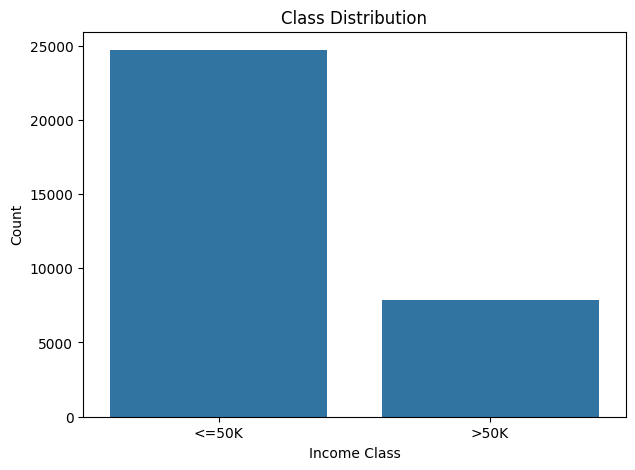

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="income")

plt.title("Class Distribution")
plt.xlabel("Income Class")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

In [13]:
df["income"] = df["income"].str.strip()

In [14]:
df["income_binary"] = df["income"].map({
    "<=50K": 0,
    ">50K": 1
})

df[["income", "income_binary"]].head()

,income,income_binary
0,<=50K,0
1,<=50K,0
2,<=50K,0
3,<=50K,0
4,<=50K,0


In [15]:
df["income_binary"].value_counts()

,count
income_binary,
0,24698
1,7839


In [16]:
X = df.drop(columns=["income", "income_binary"])
y = df["income_binary"]

In [17]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (32537, 14)
y shape: (32537,)


In [18]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

Categorical features:
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 26029
Testing rows: 6508


In [20]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [21]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

In [22]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [23]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=RANDOM_STATE
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'fnlwgt',
                                                   'education_num',
                                                   'capital_gain',
                                                   'capital_loss',
                                                   'hours_per_week']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['workclass', 'education',
                                                   'marital_status',
                                                   'occupation', 'relationship',
                                                   'race', 'sex',
                                                   'native_country'])])),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

In [24]:
y_pred_lr = logistic_model.predict(X_test)
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

In [25]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeClassifier(
                random_state=RANDOM_STATE
            )
        )
    ]
)

decision_tree_model.fit(X_train, y_train)

y_pred_dt = decision_tree_model.predict(X_test)
y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

In [45]:
knn_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            KNeighborsClassifier(n_neighbors=5)
        )
    ]
)

knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)
y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

In [46]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [47]:
nb_model = GaussianNB()

nb_model.fit(X_train_processed, y_train)

y_pred_nb = nb_model.predict(X_test_processed)
y_prob_nb = nb_model.predict_proba(X_test_processed)[:, 1]

In [48]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

In [30]:
def evaluate_model(model_name, y_true, y_pred, y_prob):
    return {
        "ML Model Name": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "AUC": roc_auc_score(y_true, y_prob),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred)
    }

In [31]:
results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        y_pred_lr,
        y_prob_lr
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        y_pred_dt,
        y_prob_dt
    )
)

results.append(
    evaluate_model(
        "KNN",
        y_test,
        y_pred_knn,
        y_prob_knn
    )
)

results.append(
    evaluate_model(
        "Naive Bayes",
        y_test,
        y_pred_nb,
        y_prob_nb
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        y_pred_rf,
        y_prob_rf
    )
)

results_df = pd.DataFrame(results)

results_df

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.856945,0.909903,0.743688,0.619898,0.676174,0.589333
1,Decision Tree,0.820682,0.753897,0.628608,0.625000,0.626799,0.508794
2,KNN,0.837892,0.865253,0.677755,0.623724,0.649618,0.545202
3,Naive Bayes,0.536109,0.749245,0.336930,0.955995,0.498255,0.329962
4,Random Forest,0.861862,0.909222,0.745055,0.648597,0.693488,0.607301


In [32]:
results_display = results_df.copy()

metric_columns = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1",
    "MCC"
]

results_display[metric_columns] = results_display[
    metric_columns
].round(4)

results_display

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8569,0.9099,0.7437,0.6199,0.6762,0.5893
1,Decision Tree,0.8207,0.7539,0.6286,0.6250,0.6268,0.5088
2,KNN,0.8379,0.8653,0.6778,0.6237,0.6496,0.5452
3,Naive Bayes,0.5361,0.7492,0.3369,0.9560,0.4983,0.3300
4,Random Forest,0.8619,0.9092,0.7451,0.6486,0.6935,0.6073


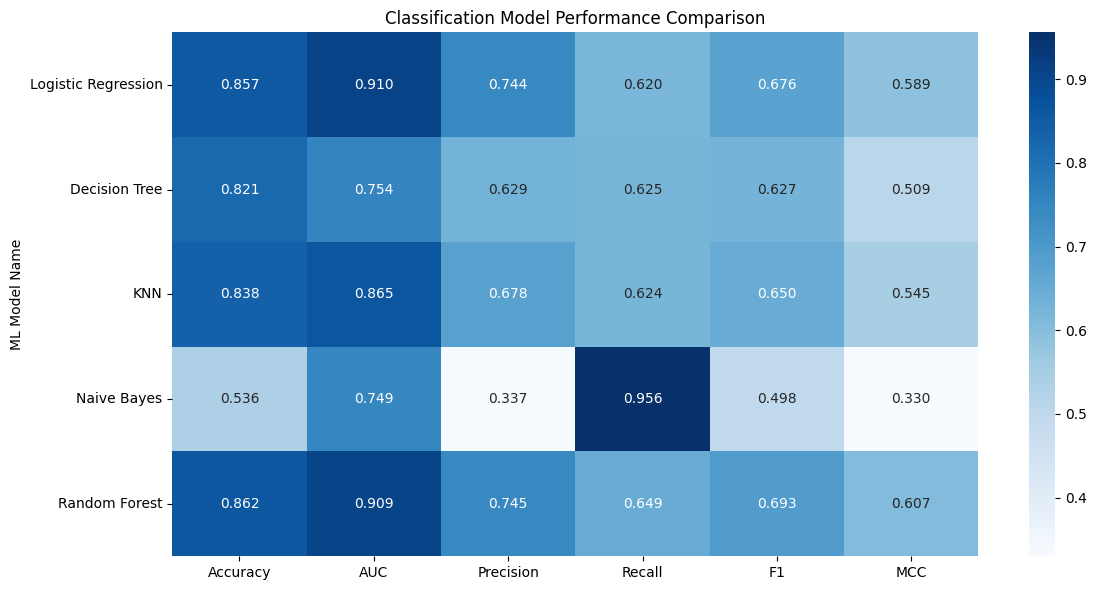

In [33]:
plt.figure(figsize=(12, 6))

heatmap_data = results_df.set_index(
    "ML Model Name"
)[metric_columns]

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="Blues"
)

plt.title("Classification Model Performance Comparison")
plt.tight_layout()
plt.show()

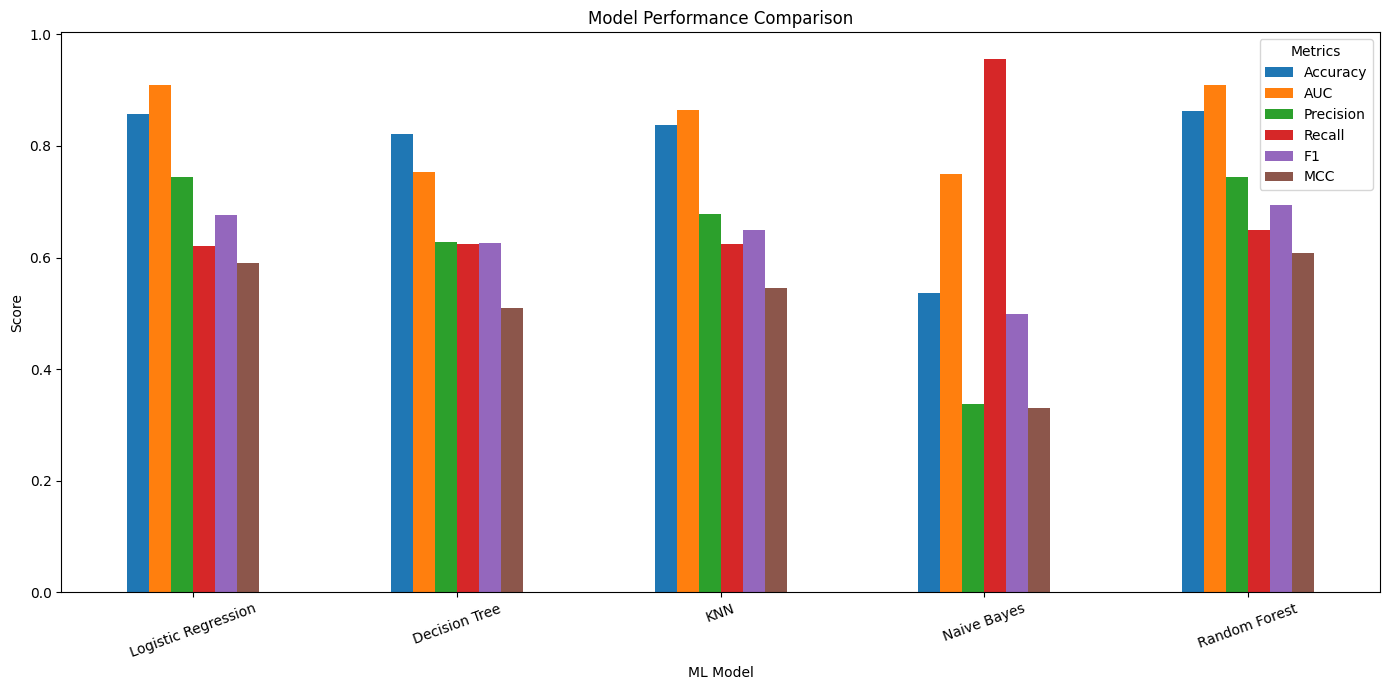

In [34]:
results_plot = results_df.set_index("ML Model Name")[metric_columns]

results_plot.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("ML Model")
plt.xticks(rotation=20)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

In [35]:
results_df["Average Score"] = results_df[
    metric_columns
].mean(axis=1)

results_df[
    ["ML Model Name", "Average Score"]
].sort_values(
    "Average Score",
    ascending=False
)

,ML Model Name,Average Score
4,Random Forest,0.744254
0,Logistic Regression,0.732657
2,KNN,0.699907
1,Decision Tree,0.660630
3,Naive Bayes,0.567749


In [36]:
winner = results_df.loc[
    results_df["Average Score"].idxmax(),
    "ML Model Name"
]

print("Overall Winner:", winner)

Overall Winner: Random Forest


In [37]:
results_df.sort_values(
    "Average Score",
    ascending=False
)

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC,Average Score
4,Random Forest,0.861862,0.909222,0.745055,0.648597,0.693488,0.607301,0.744254
0,Logistic Regression,0.856945,0.909903,0.743688,0.619898,0.676174,0.589333,0.732657
2,KNN,0.837892,0.865253,0.677755,0.623724,0.649618,0.545202,0.699907
1,Decision Tree,0.820682,0.753897,0.628608,0.625000,0.626799,0.508794,0.660630
3,Naive Bayes,0.536109,0.749245,0.336930,0.955995,0.498255,0.329962,0.567749


Logistic Regression:
Strong baseline model with balanced performance across metrics.

Decision Tree:
Good interpretability but may show weaker generalization.

KNN:
Performance depends strongly on scaling and neighborhood structure.

Naive Bayes:
Fast model based on feature-distribution assumptions.

Random Forest:
Ensemble method that may provide stronger overall performance.

In [49]:
test_data = X_test.copy()

test_data["income_binary"] = y_test.values

test_data.to_csv(
    "test_data.csv",
    index=False
)

print("test_data.csv created")

test_data.csv created


In [50]:
from google.colab import files

files.download("test_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
results_df.to_csv(
    "metrics.csv",
    index=False
)

files.download("metrics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:
df.to_csv(
    "adult_cleaned.csv",
    index=False
)

In [53]:
files.download("adult_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>